# Heart Disease Prediction - ML Pipeline

In this notebook I built the complete machine learning part of the project:

1. Data download
2. Missing values
3. Data cleaning
4. Exploratory Data Analysis (EDA)
5. Feature engineering
6. Models and tuning settings
7. Model training with MLflow tracking
8. Results, model selection and saving
9. Inference
10. Test requests to the deployed API

Cells tagged `functions` contain only definitions; the unit tests in `test/` reuse them.

In [1]:
import json
import os
import random
import time
import urllib.request
import warnings

import joblib
import matplotlib.pyplot as plt
import mlflow
import mlflow.sklearn
import pandas as pd
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    accuracy_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# MLflow prints a hint because the predictions (0/1) are whole numbers; it is not an error
warnings.filterwarnings("ignore", message="Hint: Inferred schema contains integer")

In [2]:
# Cleveland subset of the UCI Heart Disease dataset (303 patients)
DATA_URL = (
    "https://archive.ics.uci.edu/ml/machine-learning-databases/"
    "heart-disease/processed.cleveland.data"
)

# The original file has no header row, so the 14 column names are added here
COLUMNS = [
    "age", "sex", "cp", "trestbps", "chol", "fbs", "restecg",
    "thalach", "exang", "oldpeak", "slope", "ca", "thal", "num",
]

RAW_PATH = "data/raw/heart_raw.csv"
CLEAN_PATH = "data/cleaned/heart_cleaned.csv"
EDA_DIR = "outputs/eda"
PLOTS_DIR = "outputs/training"
MODEL_PATH = "models/model.joblib"
METRICS_PATH = "models/metrics.json"

# Continuous measurements -> scaled
NUMERIC_COLS = ["age", "trestbps", "chol", "thalach", "oldpeak", "ca"]

# Category codes (e.g. chest pain type 1-4) -> one-hot encoded
CATEGORICAL_COLS = ["sex", "cp", "fbs", "restecg", "exang", "slope", "thal"]

TARGET_COL = "target"

## 1. Data download

I downloaded the Cleveland subset of the UCI Heart Disease dataset. I chose this subset because it is the standard, most complete version; the other hospital subsets have most values missing in several columns.

In [3]:
os.makedirs("data/raw", exist_ok=True)

raw = pd.read_csv(DATA_URL, header=None, names=COLUMNS)
raw.to_csv(RAW_PATH, index=False)

print(f"Downloaded {len(raw)} rows and saved them to {RAW_PATH}")
raw.head()

Downloaded 303 rows and saved them to data/raw/heart_raw.csv


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


## 2. Missing values

Missing values in this dataset are stored as `?`.

In [4]:
missing = (raw == "?").sum()
missing[missing > 0]

ca      4
thal    2
dtype: int64

## 3. Data cleaning

- Missing values appeared only in `ca` and `thal` (6 rows). Since this is a very small share of the data, I removed those rows instead of filling them in.
- I removed duplicate rows.
- I converted the target `num` (0-4) into a binary `target`: 0 = no disease, 1 = disease.

In [5]:
def clean_data(df):
    """Returns a cleaned copy of the raw data."""
    df = df.copy()

    # to_numeric turns every "?" into NaN (missing)
    for col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")

    df = df.dropna()
    df = df.drop_duplicates()

    # 0 = no disease, 1-4 = disease -> binary target
    df[TARGET_COL] = (df["num"] > 0).astype(int)
    df = df.drop(columns=["num"])

    # Category codes are stored as decimals (e.g. 3.0), converted to whole numbers
    for col in CATEGORICAL_COLS:
        df[col] = df[col].astype(int)

    return df.reset_index(drop=True)

In [6]:
os.makedirs("data/cleaned", exist_ok=True)

df = clean_data(raw)
df.to_csv(CLEAN_PATH, index=False)

print(f"Cleaned data: {df.shape[0]} rows, saved to {CLEAN_PATH}")
df.describe().round(2)

Cleaned data: 297 rows, saved to data/cleaned/heart_cleaned.csv


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
count,297.00,297.00,297.00,297.00,297.00,297.00,297.00,297.00,297.00,297.00,297.00,297.00,297.00,297.00
mean,54.54,0.68,3.16,131.69,247.35,0.14,1.00,149.60,0.33,1.06,1.60,0.68,4.73,0.46
std,9.05,0.47,0.96,17.76,52.00,0.35,0.99,22.94,0.47,1.17,0.62,0.94,1.94,0.50
min,29.00,0.00,1.00,94.00,126.00,0.00,0.00,71.00,0.00,0.00,1.00,0.00,3.00,0.00
25%,48.00,0.00,3.00,120.00,211.00,0.00,0.00,133.00,0.00,0.00,1.00,0.00,3.00,0.00
50%,56.00,1.00,3.00,130.00,243.00,0.00,1.00,153.00,0.00,0.80,2.00,0.00,3.00,0.00
75%,61.00,1.00,4.00,140.00,276.00,0.00,2.00,166.00,1.00,1.60,2.00,1.00,7.00,1.00
max,77.00,1.00,4.00,200.00,564.00,1.00,2.00,202.00,1.00,6.20,3.00,3.00,7.00,1.00


## 4. Exploratory Data Analysis (EDA)

The charts are shown here and also saved in `outputs/eda/` for the report.

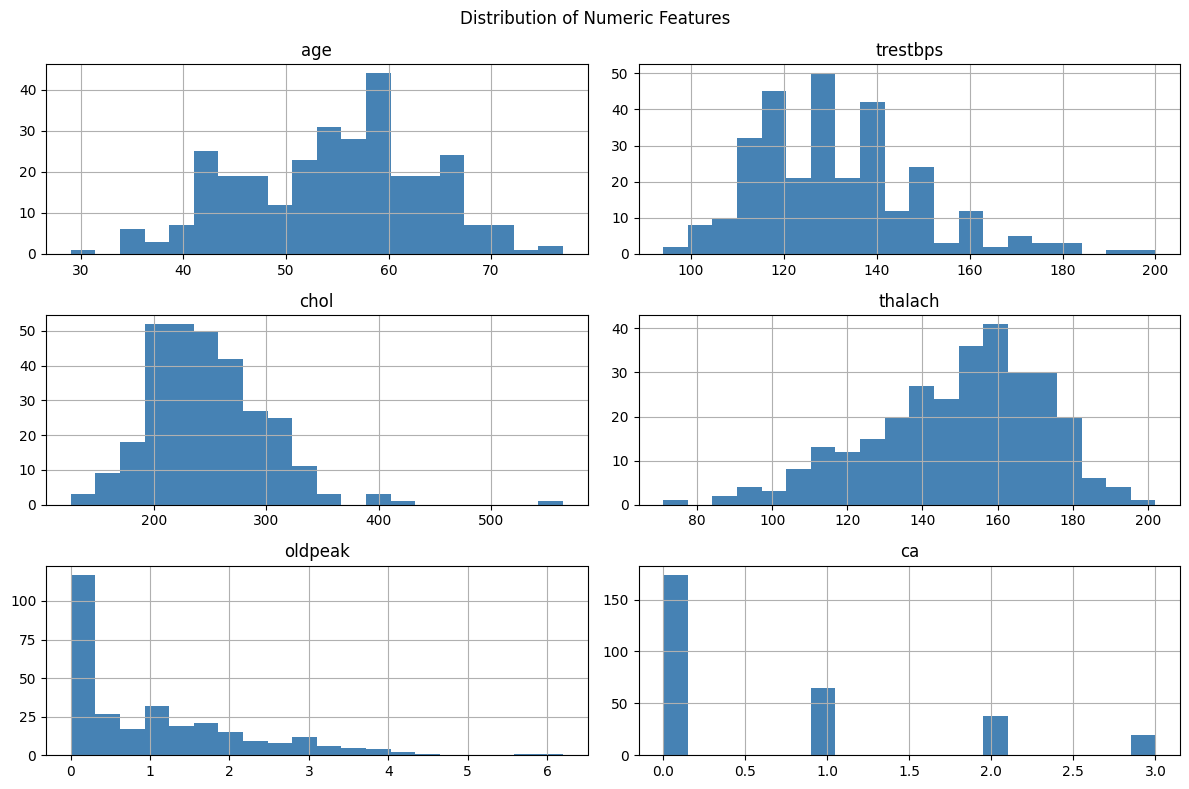

In [7]:
os.makedirs(EDA_DIR, exist_ok=True)

# Histograms of the numeric features
df[NUMERIC_COLS].hist(bins=20, figsize=(12, 8), color="steelblue")
plt.suptitle("Distribution of Numeric Features")
plt.tight_layout()
plt.savefig(f"{EDA_DIR}/histograms.png")
plt.show()

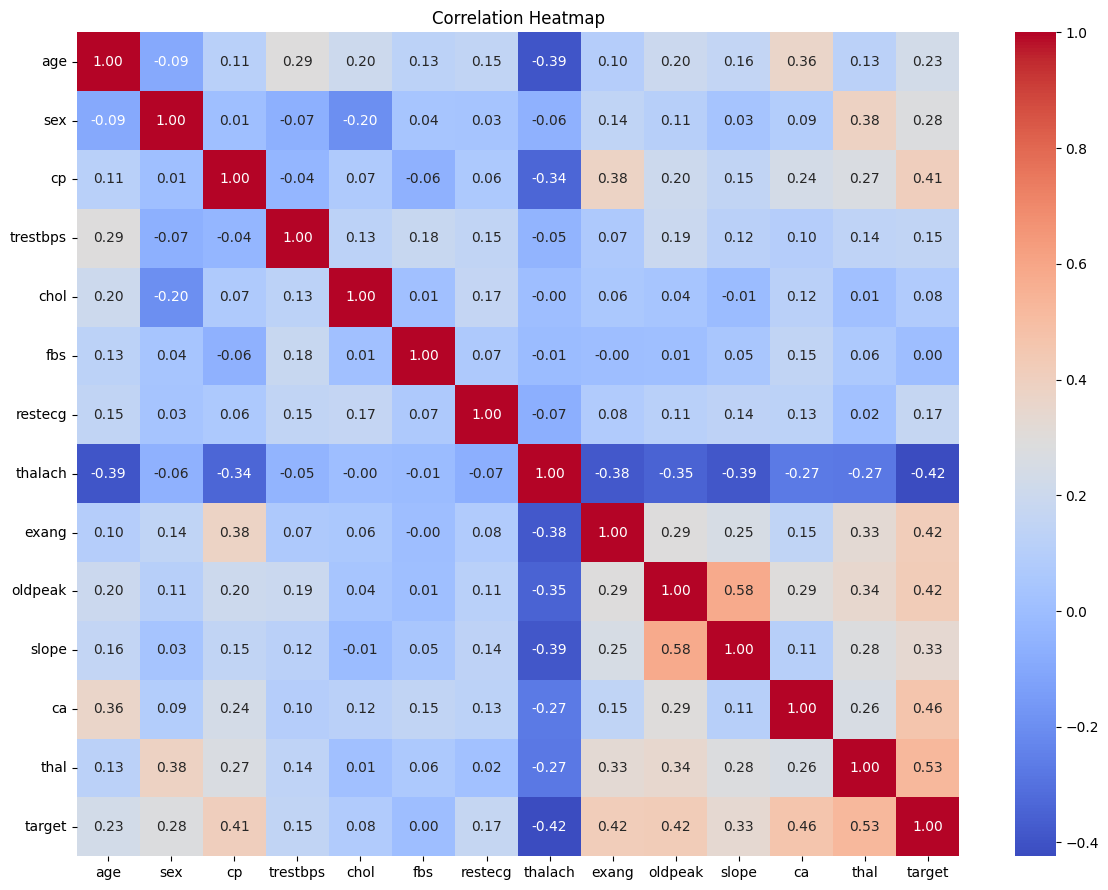

In [8]:
# Correlation heatmap of all columns
plt.figure(figsize=(12, 9))
sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.savefig(f"{EDA_DIR}/correlation_heatmap.png")
plt.show()

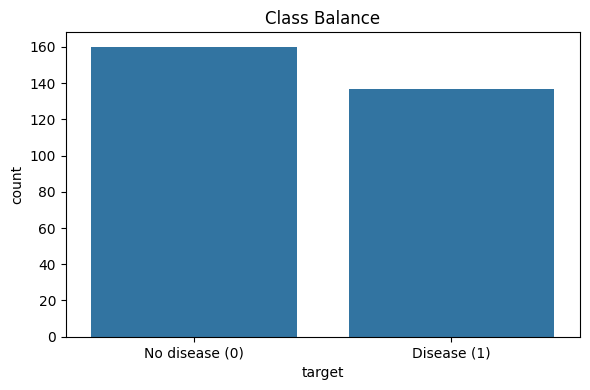

target
0    160
1    137
Name: count, dtype: int64

In [9]:
# Class balance (patients with and without disease)
plt.figure(figsize=(6, 4))
sns.countplot(x="target", data=df)
plt.xticks([0, 1], ["No disease (0)", "Disease (1)"])
plt.title("Class Balance")
plt.tight_layout()
plt.savefig(f"{EDA_DIR}/class_balance.png")
plt.show()

df[TARGET_COL].value_counts()

### EDA observations

- **Class balance:** 160 patients without disease (54%) and 137 with disease (46%). The classes are close to balanced, so I did not need resampling or class weights, and accuracy is a meaningful metric here (I still report precision, recall and ROC-AUC).
- **Features most related to `target`:** `thal` (0.53), `ca` (0.46), `exang` (0.42), `oldpeak` (0.42) and `cp` (0.41) have the strongest positive correlation. `thalach` (maximum heart rate) has a strong negative correlation (-0.42): patients who reach a lower heart rate during exercise are more likely to have disease.
- **Weak features:** `fbs` (0.00) and `chol` (0.08) are almost unrelated to the target on their own. I kept them, because a feature can still help in combination with others, and the dataset is small enough that dropping features gives little benefit.
- **Correlation between features:** the strongest pair is `oldpeak` and `slope` (0.58); all other pairs are below 0.40. There is no strong multicollinearity, so I kept all 13 features.
- **Distributions:** `chol` (skew 1.12) and `oldpeak` (skew 1.25) are right-skewed with a few high values (cholesterol up to 564). These are possible real measurements, so I did not remove them; StandardScaler puts them on the same scale as the other features.
- Note: for categorical codes such as `cp` and `thal` the correlation only gives a rough idea, because their numbers are labels, not amounts. This is why they are one-hot encoded in the next step.

## 5. Feature engineering

- I scaled the numeric features with **StandardScaler**, so features with large values (like cholesterol) do not dominate the model.
- I one-hot encoded the categorical features, because their numbers are category labels, not amounts.
- The preprocessing and the model are combined in one scikit-learn **Pipeline**, so new data always gets exactly the same transformations as the training data.

In [10]:
def build_preprocessor():
    """Scales numeric columns and one-hot encodes categorical columns."""
    return ColumnTransformer([
        ("numeric", StandardScaler(), NUMERIC_COLS),
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore", sparse_output=False),
            CATEGORICAL_COLS,
        ),
    ])


def build_pipeline(model):
    """Preprocessing + model in one object, so both are saved together."""
    return Pipeline([
        ("preprocess", build_preprocessor()),
        ("model", model),
    ])

## 6. Models and tuning settings

I trained two models:

- **Logistic Regression** - a simple, interpretable baseline.
- **Random Forest** - can capture non-linear patterns between features.

Each model is tuned with **GridSearchCV using 5-fold stratified cross-validation**, and evaluated with accuracy, precision, recall and ROC-AUC.

In [11]:
# The two models compared, with the settings tried by GridSearchCV
MODELS = {
    "logistic_regression": (
        LogisticRegression(max_iter=1000),
        {"model__C": [0.01, 0.1, 1, 10]},
    ),
    "random_forest": (
        RandomForestClassifier(random_state=42),
        {
            "model__n_estimators": [100, 200],
            "model__max_depth": [None, 5, 10],
            "model__min_samples_split": [2, 5],
        },
    ),
}

METRICS = ["accuracy", "precision", "recall", "roc_auc"]

In [12]:
def evaluate(model, X, y):
    """Returns the test-set metrics of a trained model."""
    predictions = model.predict(X)
    probabilities = model.predict_proba(X)[:, 1]
    return {
        "test_accuracy": float(accuracy_score(y, predictions)),
        "test_precision": float(precision_score(y, predictions)),
        "test_recall": float(recall_score(y, predictions)),
        "test_roc_auc": float(roc_auc_score(y, probabilities)),
    }


def save_plots(model, X, y, name):
    """Saves and shows a confusion matrix and an ROC curve, returns the file paths."""
    os.makedirs(PLOTS_DIR, exist_ok=True)

    cm_path = f"{PLOTS_DIR}/{name}_confusion_matrix.png"
    ConfusionMatrixDisplay.from_estimator(model, X, y)
    plt.title(f"Confusion Matrix - {name}")
    plt.savefig(cm_path)
    plt.show()

    roc_path = f"{PLOTS_DIR}/{name}_roc_curve.png"
    RocCurveDisplay.from_estimator(model, X, y)
    plt.title(f"ROC Curve - {name}")
    plt.savefig(roc_path)
    plt.show()

    return [cm_path, roc_path]


def train_model(name, model, param_grid, X_train, X_test, y_train, y_test):
    """Tunes one model with 5-fold cross-validation and logs it to MLflow."""
    print(f"\nTraining {name} ...")

    search = GridSearchCV(
        build_pipeline(model),
        param_grid,
        cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42),
        scoring=METRICS,
        refit="roc_auc",  # best settings chosen by ROC-AUC
    )
    search.fit(X_train, y_train)
    best_model = search.best_estimator_

    # Cross-validation scores of the best settings
    i = search.best_index_
    cv_scores = {f"cv_{m}": float(search.cv_results_[f"mean_test_{m}"][i]) for m in METRICS}

    # Scores on the 20% test set that was not used for training
    test_scores = evaluate(best_model, X_test, y_test)

    # One MLflow run per model: parameters, metrics, plots and the model itself
    with mlflow.start_run(run_name=name):
        mlflow.log_param("model_type", name)
        mlflow.log_params(search.best_params_)
        mlflow.log_metrics(cv_scores)
        mlflow.log_metrics(test_scores)

        for plot_path in save_plots(best_model, X_test, y_test, name):
            mlflow.log_artifact(plot_path)

        results_path = f"{PLOTS_DIR}/{name}_grid_search_results.csv"
        pd.DataFrame(search.cv_results_).to_csv(results_path, index=False)
        mlflow.log_artifact(results_path)

        # The input example also saves the 13 input columns with the model
        mlflow.sklearn.log_model(best_model, "model", input_example=X_train.head(3))

    print(f"Best settings: {search.best_params_}")
    return best_model, cv_scores, test_scores

## 7. Model training with MLflow tracking

I split the data 80/20, stratified so both parts keep the same disease / no-disease ratio. Each model is logged as one MLflow run in the `heart-disease` experiment.

2026/10/20 17:02:52 INFO mlflow.tracking.fluent: Experiment with name 'heart-disease' does not exist. Creating a new experiment.


Training rows: 237, test rows: 60

Training logistic_regression ...


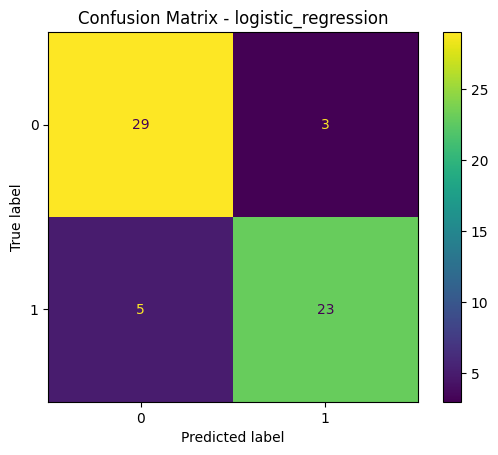

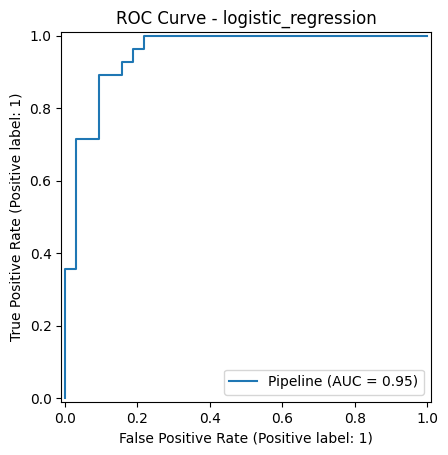

Best settings: {'model__C': 0.1}

Training random_forest ...


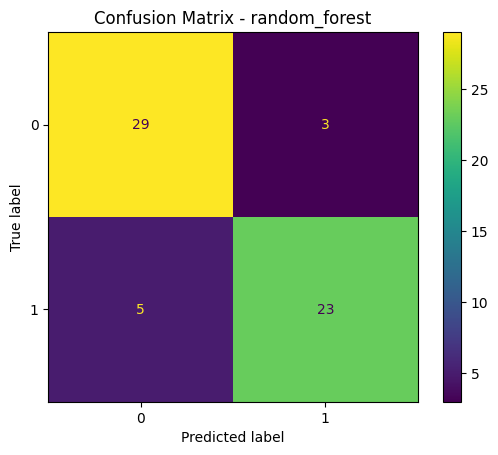

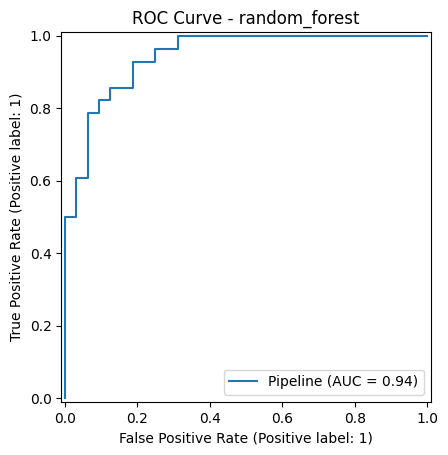

Best settings: {'model__max_depth': 5, 'model__min_samples_split': 2, 'model__n_estimators': 200}


In [13]:
X = df.drop(columns=[TARGET_COL])
y = df[TARGET_COL]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)
print(f"Training rows: {len(X_train)}, test rows: {len(X_test)}")

mlflow.set_experiment("heart-disease")

results = {}
trained = {}
for name, (model, param_grid) in MODELS.items():
    best_model, cv_scores, test_scores = train_model(
        name, model, param_grid, X_train, X_test, y_train, y_test
    )
    trained[name] = best_model
    results[name] = {**cv_scores, **test_scores}

## 8. Results, model selection and saving

I selected the final model by **cross-validated ROC-AUC**, because it measures how well the model separates patients with and without disease across all thresholds. The selected pipeline (preprocessing + model) is saved to `models/model.joblib`, and all scores to `models/metrics.json`.

In [14]:
results_table = pd.DataFrame(results).T
# Chosen on the unrounded scores, so two close models are not treated as a tie
best_name = results_table["cv_roc_auc"].idxmax()
print(f"Selected model: {best_name}")

os.makedirs("models", exist_ok=True)
joblib.dump(trained[best_name], MODEL_PATH)
with open(METRICS_PATH, "w") as f:
    json.dump({"selected_model": best_name, "results": results}, f, indent=2)
print(f"Model saved to {MODEL_PATH}, metrics saved to {METRICS_PATH}")

results_table.round(3)

Selected model: random_forest
Model saved to models/model.joblib, metrics saved to models/metrics.json


,cv_accuracy,cv_precision,cv_recall,cv_roc_auc,test_accuracy,test_precision,test_recall,test_roc_auc
logistic_regression,0.835,0.858,0.778,0.896,0.867,0.885,0.821,0.952
random_forest,0.814,0.834,0.760,0.896,0.867,0.885,0.821,0.944


### Model comparison

| Metric | Logistic Regression | Random Forest |
|---|---|---|
| Best settings | `C = 0.1` | `max_depth = 5`, `min_samples_split = 2`, `n_estimators = 200` |
| CV accuracy | 0.835 | 0.814 |
| CV precision | 0.858 | 0.834 |
| CV recall | 0.778 | 0.760 |
| CV ROC-AUC | 0.8955 | **0.8959** |
| Test accuracy | 0.867 | 0.867 |
| Test precision | 0.885 | 0.885 |
| Test recall | 0.821 | 0.821 |
| Test ROC-AUC | 0.952 | 0.944 |

- **Tuning:** for Logistic Regression, `C = 0.1` (moderate regularisation) was best; weaker (`C = 10`) and stronger (`C = 0.01`) regularisation scored slightly lower. For Random Forest, limiting the tree depth helped: unlimited depth with `min_samples_split = 2` scored the lowest (0.872), because the trees overfit the small training set.
- **Selection:** following my rule (highest cross-validated ROC-AUC), **Random Forest** was selected and saved. The difference is very small (0.0003), much smaller than the variation between folds (standard deviation about 0.06-0.07), so the two models perform practically the same on this dataset.
- On the test set both models make the same number of correct predictions; Logistic Regression has a slightly higher test ROC-AUC. Since the test set has only 60 patients, I based the choice on cross-validation, which uses all training data, and not on the test set.
- Recall (0.82 on the test set) is lower than precision, so the model misses some patients who have disease. In a medical setting this matters, and lowering the decision threshold would be a possible next step.

The runs can be compared in the MLflow UI: `mlflow ui` in the project folder, then http://localhost:5000.

## 9. Inference

The saved model is loaded and used to predict for the patient in `sample_input.json`. The confidence is the probability of the predicted class.

In [15]:
def predict(patient, model_path=MODEL_PATH):
    """patient: a dict with the 13 feature values."""
    model = joblib.load(model_path)
    data = pd.DataFrame([patient])

    prediction = int(model.predict(data)[0])
    confidence = float(model.predict_proba(data)[0].max())
    return {"prediction": prediction, "confidence": round(confidence, 4)}

In [16]:
with open("sample_input.json") as f:
    patient = json.load(f)

print("Input:", patient)
print("Result:", predict(patient))

Input: {'age': 63, 'sex': 1, 'cp': 1, 'trestbps': 145, 'chol': 233, 'fbs': 1, 'restecg': 2, 'thalach': 150, 'exang': 0, 'oldpeak': 2.3, 'slope': 3, 'ca': 0, 'thal': 6}
Result: {'prediction': 0, 'confidence': 0.6976}


## 10. Test requests to the deployed API

This cell sends 50 requests to the running API so the Prometheus and Grafana charts have data. It runs only when `RUN_REQUESTS = True`, after the API is deployed (Kubernetes: port 8080, Docker: port 8000).

In [17]:
API_URL = "http://localhost:8080"
RUN_REQUESTS = False


def random_patient():
    return {
        "age": random.randint(30, 77),
        "sex": random.randint(0, 1),
        "cp": random.randint(1, 4),
        "trestbps": random.randint(95, 190),
        "chol": random.randint(130, 400),
        "fbs": random.randint(0, 1),
        "restecg": random.choice([0, 1, 2]),
        "thalach": random.randint(90, 200),
        "exang": random.randint(0, 1),
        "oldpeak": round(random.uniform(0, 5), 1),
        "slope": random.randint(1, 3),
        "ca": random.randint(0, 3),
        "thal": random.choice([3, 6, 7]),
    }


def send_test_requests(n=50):
    for i in range(n):
        body = json.dumps(random_patient()).encode()
        request = urllib.request.Request(
            f"{API_URL}/predict", data=body, headers={"Content-Type": "application/json"}
        )
        with urllib.request.urlopen(request) as response:
            print(i + 1, response.read().decode())
        time.sleep(0.2)


if RUN_REQUESTS:
    send_test_requests()